In [13]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [7]:
from google.colab import files
uploaded = files.upload()

Saving usa_00002.csv.gz to usa_00002.csv.gz


In [21]:
print(os.listdir("/content"))

['.config', 'ipums_extract', 'drive', 'usa_00002.csv.gz', 'sample_data']


In [22]:
import pandas as pd

data_path = "/content/usa_00002.csv.gz"

df = pd.read_csv(data_path, nrows=20)
print(df.shape)
print(df.columns.tolist())
print(df.head())

(20, 40)
['US2017A_AGEP', 'US2017A_SCHL', 'US2017A_SEX', 'US2017A_WAGP', 'US2017A_PERNP', 'US2018A_AGEP', 'US2018A_SCHL', 'US2018A_SEX', 'US2018A_WAGP', 'US2018A_PERNP', 'US2019A_AGEP', 'US2019A_SCHL', 'US2019A_SEX', 'US2019A_WAGP', 'US2019A_PERNP', 'US2020A_AGEP', 'US2020A_SCHL', 'US2020A_SEX', 'US2020A_WAGP', 'US2020A_PERNP', 'US2021A_AGEP', 'US2021A_SCHL', 'US2021A_SEX', 'US2021A_WAGP', 'US2021A_PERNP', 'US2022A_AGEP', 'US2022A_SCHL', 'US2022A_SEX', 'US2022A_WAGP', 'US2022A_PERNP', 'US2023A_AGEP', 'US2023A_SCHL', 'US2023A_SEX', 'US2023A_WAGP', 'US2023A_PERNP', 'US2024A_AGEP', 'US2024A_SCHL', 'US2024A_SEX', 'US2024A_WAGP', 'US2024A_PERNP']
   US2017A_AGEP US2017A_SCHL  US2017A_SEX US2017A_WAGP US2017A_PERNP  \
0            73           10            1       000000       0000000   
1            31           21            2       038500       0038500   
2            41           17            1       072000       0072000   
3            48           16            2       000000       0

In [24]:
import gzip, shutil, os

gz_path = "/content/usa_00002.csv.gz"
csv_path = "/content/usa_00002.csv"

with gzip.open(gz_path, "rb") as f_in:
    with open(csv_path, "wb") as f_out:
        shutil.copyfileobj(f_in, f_out)

print(os.path.getsize(csv_path))

1750311080


In [25]:

print(df.columns.tolist())

['US2017A_AGEP', 'US2017A_SCHL', 'US2017A_SEX', 'US2017A_WAGP', 'US2017A_PERNP', 'US2018A_AGEP', 'US2018A_SCHL', 'US2018A_SEX', 'US2018A_WAGP', 'US2018A_PERNP', 'US2019A_AGEP', 'US2019A_SCHL', 'US2019A_SEX', 'US2019A_WAGP', 'US2019A_PERNP', 'US2020A_AGEP', 'US2020A_SCHL', 'US2020A_SEX', 'US2020A_WAGP', 'US2020A_PERNP', 'US2021A_AGEP', 'US2021A_SCHL', 'US2021A_SEX', 'US2021A_WAGP', 'US2021A_PERNP', 'US2022A_AGEP', 'US2022A_SCHL', 'US2022A_SEX', 'US2022A_WAGP', 'US2022A_PERNP', 'US2023A_AGEP', 'US2023A_SCHL', 'US2023A_SEX', 'US2023A_WAGP', 'US2023A_PERNP', 'US2024A_AGEP', 'US2024A_SCHL', 'US2024A_SEX', 'US2024A_WAGP', 'US2024A_PERNP']


In [2]:
import pandas as pd
df = pd.read_csv("/content/usa_00002.csv.gz", nrows=200000)

In [4]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
import seaborn as sns
import matplotlib.pyplot as plt

print(df.shape)
print(df.head())

(200000, 40)
   US2017A_AGEP US2017A_SCHL  US2017A_SEX US2017A_WAGP US2017A_PERNP  \
0            73           10            1       000000       0000000   
1            31           21            2       038500       0038500   
2            41           17            1       072000       0072000   
3            48           16            2       000000       0000000   
4            16           13            1       000000       0000000   

   US2018A_AGEP  US2018A_SCHL  US2018A_SEX  US2018A_WAGP  US2018A_PERNP  ...  \
0           NaN           NaN          NaN           NaN            NaN  ...   
1           NaN           NaN          NaN           NaN            NaN  ...   
2           NaN           NaN          NaN           NaN            NaN  ...   
3           NaN           NaN          NaN           NaN            NaN  ...   
4           NaN           NaN          NaN           NaN            NaN  ...   

   US2023A_AGEP  US2023A_SCHL  US2023A_SEX  US2023A_WAGP  US2023A_PERNP  

In [5]:
years = [2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024]

parts = []

for y in years:
    prefix = f"US{y}A_"
    cols = {
        'age':  prefix + 'AGEP',
        'schl': prefix + 'SCHL',
        'sex':  prefix + 'SEX',
        'wagp': prefix + 'WAGP',
        'pernp':prefix + 'PERNP',
    }

    # 只取这一年存在的列
    avail = {k:v for k,v in cols.items() if v in df.columns}
    if not avail:
        continue

    tmp = df[list(avail.keys() if False else avail.values())].copy()
    tmp = tmp.rename(columns={v:k for k,v in avail.items()})
    tmp['year'] = y
    parts.append(tmp)

df_long = pd.concat(parts, ignore_index=True)

print(df_long.shape)
print(df_long.head())
print(df_long.dtypes)

(1600000, 6)
    age schl  sex    wagp    pernp  year
0  73.0   10  1.0  000000  0000000  2017
1  31.0   21  2.0  038500  0038500  2017
2  41.0   17  1.0  072000  0072000  2017
3  48.0   16  2.0  000000  0000000  2017
4  16.0   13  1.0  000000  0000000  2017
age      float64
schl      object
sex      float64
wagp      object
pernp     object
year       int64
dtype: object


In [7]:
for c in ['wagp', 'pernp', 'age', 'schl', 'sex']:
    if c in df_long.columns:
        df_long[c] = pd.to_numeric(df_long[c], errors='coerce')

In [8]:
df_long['income'] = df_long['wagp'].where(df_long['wagp'] > 0, df_long['pernp'])

df_long = df_long[df_long['age'].between(25, 64)]
df_long = df_long[df_long['income'] > 0]
df_long = df_long[df_long['income'] < 5_000_000]
df_long = df_long.dropna(subset=['income', 'schl', 'age', 'sex'])

print(df_long.shape)
print(df_long.dtypes)
print(df_long.head())

(76176, 7)
age       float64
schl      float64
sex       float64
wagp      float64
pernp     float64
year        int64
income    float64
dtype: object
     age  schl  sex     wagp    pernp  year   income
1   31.0  21.0  2.0  38500.0  38500.0  2017  38500.0
2   41.0  17.0  1.0  72000.0  72000.0  2017  72000.0
5   37.0  16.0  2.0  18000.0  18000.0  2017  18000.0
10  32.0  16.0  1.0  65000.0  65000.0  2017  65000.0
11  54.0  20.0  2.0  57000.0  57000.0  2017  57000.0


In [9]:
def simplify_educ(code):
    if pd.isna(code):
        return np.nan
    code = int(code)
    if code <= 15:
        return 'Less than HS'
    elif code in [16, 17]:
        return 'High School'
    elif code in [18, 19]:
        return 'Some College'
    elif code == 20:
        return 'Associate'
    elif code == 21:
        return 'Bachelor'
    elif code >= 22:
        return 'Graduate'
    else:
        return np.nan

df_long['educ_group'] = df_long['schl'].apply(simplify_educ)
df_long = df_long.dropna(subset=['educ_group'])

df_long['sex_label'] = df_long['sex'].map({1: 'Male', 2: 'Female'})
df_long = df_long.dropna(subset=['sex_label'])

print(df_long['schl'].value_counts().sort_index())
print(df_long['educ_group'].value_counts())

schl
1.0       860
2.0        15
3.0        11
4.0        17
5.0        64
6.0       138
7.0        79
8.0       128
9.0       723
10.0      180
11.0      535
12.0      904
13.0      930
14.0     1213
15.0     1398
16.0    14612
17.0     3011
18.0     5346
19.0    12261
20.0     7238
21.0    16541
22.0     6941
23.0     1818
24.0     1213
Name: count, dtype: int64
educ_group
High School     17623
Some College    17607
Bachelor        16541
Graduate         9972
Associate        7238
Less than HS     7195
Name: count, dtype: int64


In [18]:
#描述性统计
desc = (
    df_long.groupby('educ_group')['income']
    .agg(['count', 'median', 'mean', 'std'])
    .reindex(['Less than HS', 'High School', 'Some College', 'Associate', 'Bachelor', 'Graduate'])
)
print(desc)

              count   median          mean           std
educ_group                                              
Less than HS   7195  22000.0  28619.150521  32952.461035
High School   17623  30000.0  36713.715031  36398.313873
Some College  17607  34300.0  43272.058840  43408.186666
Associate      7238  39000.0  46118.993368  40804.826811
Bachelor      16541  52000.0  68681.885013  67625.227349
Graduate       9972  70000.0  95283.633173  92312.915477


In [19]:
desc_display = desc.copy()
desc_display['median'] = desc_display['median'].apply(lambda x: f"${x:,.0f}")
desc_display['mean']   = desc_display['mean'].apply(lambda x: f"${x:,.0f}")
desc_display['std']    = desc_display['std'].apply(lambda x: f"${x:,.0f}")
desc_display['count']  = desc_display['count'].apply(lambda x: f"{x:,}")
print(desc_display)

               count   median     mean      std
educ_group                                     
Less than HS   7,195  $22,000  $28,619  $32,952
High School   17,623  $30,000  $36,714  $36,398
Some College  17,607  $34,300  $43,272  $43,408
Associate      7,238  $39,000  $46,119  $40,805
Bachelor      16,541  $52,000  $68,682  $67,625
Graduate       9,972  $70,000  $95,284  $92,313


In [11]:
#回归
model = smf.ols(
    'np.log(income + 1) ~ C(educ_group) + age + C(sex_label) + C(year)',
    data=df_long
).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:     np.log(income + 1)   R-squared:                       0.158
Model:                            OLS   Adj. R-squared:                  0.157
Method:                 Least Squares   F-statistic:                     2035.
Date:                Thu, 17 Sep 2026   Prob (F-statistic):               0.00
Time:                        18:07:12   Log-Likelihood:            -1.1071e+05
No. Observations:               76176   AIC:                         2.214e+05
Df Residuals:                   76168   BIC:                         2.215e+05
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
Intercept     

              count   median          mean           std
educ_group                                              
Less than HS   7195  22000.0  28619.150521  32952.461035
High School   17623  30000.0  36713.715031  36398.313873
Some College  17607  34300.0  43272.058840  43408.186666
Associate      7238  39000.0  46118.993368  40804.826811
Bachelor      16541  52000.0  68681.885013  67625.227349
Graduate       9972  70000.0  95283.633173  92312.915477


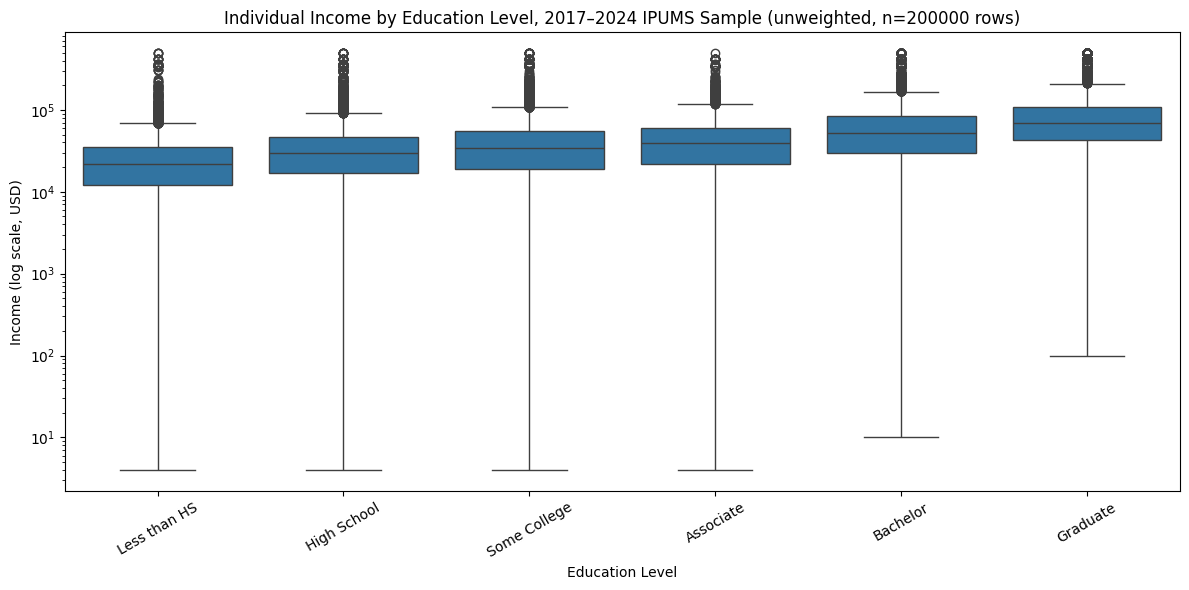

In [15]:
# 图
plt.figure(figsize=(12, 6))
sns.boxplot(
    data=df_long,
    x='educ_group',
    y='income',
    order=['Less than HS', 'High School', 'Some College', 'Associate', 'Bachelor', 'Graduate']
)
desc = (
    df_long.groupby('educ_group')['income']
    .agg(['count', 'median', 'mean', 'std'])
    .reindex(['Less than HS', 'High School', 'Some College', 'Associate', 'Bachelor', 'Graduate'])
)
print(desc)
plt.yscale('log')
plt.title('Individual Income by Education Level, 2017–2024 IPUMS Sample (unweighted, n=200000 rows)')
plt.xlabel('Education Level')
plt.ylabel('Income (log scale, USD)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig('/content/ipums_education_income.png', dpi=150)
plt.show()

In [21]:
# 看每组男女占比
tab = (
    pd.crosstab(df_long['educ_group'], df_long['sex_label'])
    .reindex(['Less than HS', 'High School', 'Some College', 'Associate', 'Bachelor', 'Graduate'])
)
tab['total'] = tab.sum(axis=1)
tab_pct = tab.iloc[:, :-1].div(tab['total'], axis=0) * 100

print(tab)
print(tab_pct.round(1))

sex_label     Female   Male  total
educ_group                        
Less than HS    2598   4597   7195
High School     7299  10324  17623
Some College    8461   9146  17607
Associate       4011   3227   7238
Bachelor        8434   8107  16541
Graduate        5218   4754   9972
sex_label     Female  Male
educ_group                
Less than HS    36.1  63.9
High School     41.4  58.6
Some College    48.1  51.9
Associate       55.4  44.6
Bachelor        51.0  49.0
Graduate        52.3  47.7


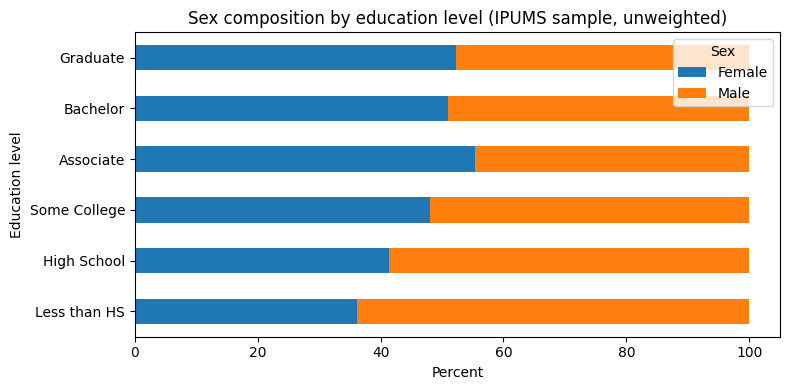

In [22]:
import matplotlib.pyplot as plt

tab_pct.plot(kind='barh', stacked=True, figsize=(8,4))
plt.xlabel('Percent')
plt.ylabel('Education level')
plt.title('Sex composition by education level (IPUMS sample, unweighted)')
plt.legend(title='Sex')
plt.tight_layout()
plt.show()

In [23]:
age_desc = (
    df_long.groupby('educ_group')['age']
    .agg(['count', 'median', 'mean', 'std', 'min', 'max'])
    .reindex(['Less than HS', 'High School', 'Some College', 'Associate', 'Bachelor', 'Graduate'])
    .round(1)
)
print(age_desc)

              count  median  mean   std   min   max
educ_group                                         
Less than HS   7195    45.0  44.9  10.9  25.0  64.0
High School   17623    46.0  44.8  11.5  25.0  64.0
Some College  17607    45.0  44.0  11.6  25.0  64.0
Associate      7238    44.0  43.9  11.3  25.0  64.0
Bachelor      16541    43.0  43.0  11.3  25.0  64.0
Graduate       9972    45.0  44.9  10.9  25.0  64.0


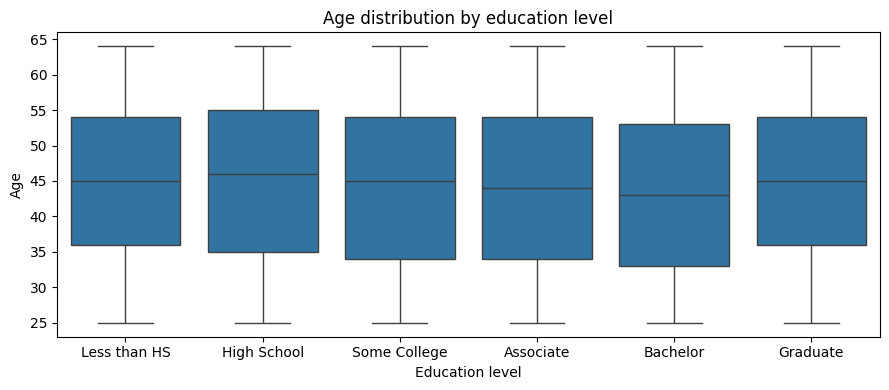

In [24]:
import seaborn as sns

plt.figure(figsize=(9,4))
sns.boxplot(data=df_long, x='educ_group', y='age',
            order=['Less than HS', 'High School', 'Some College', 'Associate', 'Bachelor', 'Graduate'])
plt.title('Age distribution by education level')
plt.xlabel('Education level')
plt.ylabel('Age')
plt.tight_layout()
plt.show()